# Лабораторно-практичне заняття №5. Частина 2
## Придушення шумів у координатних даних: фільтр Калмана

**Перед початком роботи:** меню **File → Save a copy in Drive** — працюйте у своїй копії.
У Блоці 1 вкажіть свій `STUDENT_NUMBER`, у Блок 3 вставте свої класи `SMA`, `EMA` і `Median` з частини 1
і запустіть усе кнопкою **▶ Run all**.

In [3]:
# --- Блок 1. Налаштування ---
import numpy as np
import matplotlib.pyplot as plt
from collections import deque   # знадобиться для медіанного фільтра

STUDENT_NUMBER = 14     # ваш номер у списку групи: від нього залежать шум і викиди

FS = 10.0               # частота вимірювань, Гц (як у GPS-приймача на 10 Гц)
DURATION = 120.0        # тривалість запису, с
NOISE_STD = 3.0         # СКВ (стандартне відхилення σ) шуму координати, м
OUTLIER_SHARE = 0.02    # частка вимірювань-викидів (стрибків на 20–40 м)

In [4]:
# --- Блок 2. Генератор даних: справжній трек і «виміряний» ---
T = np.arange(0, DURATION, 1 / FS)


def true_track(t):
    """Справжній трек, м: прямий проїзд, поворот на 90°, «змійка» з об'їздами, знову прямо."""
    x, y = np.zeros_like(t), np.zeros_like(t)
    v = 10.0                                         # м/с
    for i, ti in enumerate(t):
        if ti < 30:                                  # прямо на схід
            x[i], y[i] = v * ti, 0.0
        elif ti < 45:                                # поворот ліворуч по дузі радіусом 95 м
            a = (ti - 30) / 15 * np.pi / 2
            x[i], y[i] = 300 + 95 * np.sin(a), 95 * (1 - np.cos(a))
        elif ti < 90:                                # на північ «змійкою»: три об'їзди ліворуч до 50 м, період 15 с
            s = ti - 45
            x[i], y[i] = 395 - 25 * (1 - np.cos(2 * np.pi * s / 15)), 95 + v * s
        else:                                        # прямо на північ
            x[i], y[i] = 395, 545 + v * (ti - 90)
    return x, y


X_TRUE, Y_TRUE = true_track(T)
rng = np.random.default_rng(STUDENT_NUMBER)
X_MEAS = X_TRUE + rng.normal(0, NOISE_STD, T.size)
Y_MEAS = Y_TRUE + rng.normal(0, NOISE_STD, T.size)
OUTLIERS = rng.random(T.size) < OUTLIER_SHARE          # де стоять викиди
OUTLIERS[0] = False                                    # перше вимірювання без викиду: з нього стартують фільтри
angle = rng.uniform(0, 2 * np.pi, T.size)
jump = rng.uniform(20, 40, T.size)
X_MEAS[OUTLIERS] += (jump * np.cos(angle))[OUTLIERS]
Y_MEAS[OUTLIERS] += (jump * np.sin(angle))[OUTLIERS]
print(f'Студент №{STUDENT_NUMBER}: {T.size} вимірювань по {1 / FS:.1f} с, викидів {OUTLIERS.sum()}')

Студент №14: 1200 вимірювань по 0.1 с, викидів 22


In [5]:
# --- Блок 3. Ваш код: потокові фільтри ---

class SMA:
    """Ковзне середнє останніх W вимірювань."""

    def __init__(self, window):
        self.window = window
        self.buffer = [0] * window
        self.index = 0
        self.count = 0
        self.total = 0.0

    def update(self, x):
        if self.count == self.window:
            self.total -= self.buffer[self.index]
        else:
            self.count += 1

        self.buffer[self.index] = x
        self.total += x
        self.index = (self.index + 1) % self.window

        return self.total / self.count


class EMA:
    """Експоненційне ковзне середнє."""

    def __init__(self, alpha):
        self.alpha = alpha
        self.previous = None

    def update(self, x):
        if self.previous is None:
            self.previous = x
        else:
            self.previous = (
                self.alpha * x
                + (1 - self.alpha) * self.previous
            )

        return self.previous


class Median:
    """Медіана останніх W вимірювань."""

    def __init__(self, window):
        self.window = window
        self.values = deque(maxlen=window)

    def update(self, x):
        self.values.append(x)
        return float(np.median(self.values))

In [6]:
# --- Блок 4. Перевірка вставлених фільтрів (не змінюйте) ---

import time


def check_filters():
    test = np.random.default_rng(7).normal(0, 1, 200).cumsum()
    expected = {
        'SMA': [test[max(0, i - 9):i + 1].mean() for i in range(test.size)],
        'Median': [np.median(test[max(0, i - 8):i + 1]) for i in range(test.size)],
    }
    ema, y = [], None
    for v in test:
        y = v if y is None else 0.3 * v + 0.7 * y
        ema.append(y)
    expected['EMA'] = ema
    passed = []
    for name, make in (('SMA', lambda: SMA(10)), ('EMA', lambda: EMA(0.3)), ('Median', lambda: Median(9))):
        if name not in globals():
            print(f'{name}: класу ще немає — вставте свої фільтри з частини 1 у Блок 3 і запустіть цю комірку ще раз.')
            continue
        try:
            f = make()
            got = [f.update(v) for v in test]
        except NotImplementedError as e:
            print(f'{name}: {e}, а потім запустіть цю комірку ще раз.')
            continue
        except Exception as e:
            print(f'{name}: помилка під час роботи фільтра — {type(e).__name__}: {e}')
            continue
        if any(g is None for g in got):
            print(f'{name}: метод update нічого не повертає — додайте return.')
            continue
        bad = np.flatnonzero(np.abs(np.array(got, dtype=float) - np.array(expected[name])) > 1e-9)
        if bad.size == 0:
            print(f'{name}: перевірка пройдена.')
            passed.append(name)
            continue
        hint = (' Підказка: коли значень парна кількість, медіана — середнє двох центральних (так рахує np.median).'
                if name == 'Median' and bad[0] < 8 and bad[0] % 2 == 1 else '')
        print(f'{name}: розбіжність з очікуваним уже на вимірюванні №{bad[0]} '
              f'(отримано {got[bad[0]]:.4f}, очікувано {expected[name][bad[0]]:.4f}).{hint}')
    if 'SMA' in passed:                      # O(1): час обробки не має залежати від розміру вікна
        def sma_time(w, n=20000):
            f, t0 = SMA(w), time.perf_counter()
            for v in range(n):
                f.update(float(v))
            return time.perf_counter() - t0
        ratio = sma_time(10_000) / sma_time(10)
        print('SMA: час обробки не залежить від W — схоже на O(1).' if ratio < 3 else
              f'SMA: з вікном 10 000 обробка в {ratio:.0f} разів повільніша, ніж з вікном 10, — '
              'схоже, ви щоразу підсумовуєте все вікно.')

check_filters()

SMA: перевірка пройдена.
EMA: перевірка пройдена.
Median: перевірка пройдена.
SMA: час обробки не залежить від W — схоже на O(1).


In [7]:
# --- Блок 5. Запуск фільтрів, похибки, рисунки (не змінюйте) ---

def apply(make_filter):
    """Пропускає трек через фільтр, окремий для x і для y; повертає (x, y)."""
    fx, fy = make_filter(), make_filter()
    xs = np.array([fx.update(v) for v in X_MEAS])
    ys = np.array([fy.update(v) for v in Y_MEAS])
    return xs, ys


def rmse(xs, ys, skip=0.0):
    """Середньоквадратична похибка положення, м (перші skip секунд не враховуються)."""
    k = T >= skip
    return float(np.sqrt(np.mean((xs[k] - X_TRUE[k]) ** 2 + (ys[k] - Y_TRUE[k]) ** 2)))


def error_spectrum(xs):
    """Амплітудний спектр похибки координати x (без середнього), м."""
    e = xs - X_TRUE
    e = e - e.mean()
    return np.fft.rfftfreq(e.size, 1 / FS), 2 * np.abs(np.fft.rfft(e)) / e.size


def max_error(xs, ys, skip=5.0):
    """Найбільша похибка положення, м, і момент, коли вона сталася, с (перші skip секунд не враховуються)."""
    k = T >= skip
    err = np.hypot(xs - X_TRUE, ys - Y_TRUE)[k]
    i = int(np.argmax(err))
    return float(err[i]), float(T[k][i])


def compare(results, title=''):
    """results — словник {назва: (x, y)}; друкує похибки і будує поворот і «змійку» крупно, похибку в часі та її спектр."""
    results = {'Виміряно': (X_MEAS, Y_MEAS), **results}
    for name, (xs, ys) in results.items():
        print(f'{name:>26}: RMSE {rmse(xs, ys, skip=5):6.2f} м')
    fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(2, 2, figsize=(14, 10), gridspec_kw={'width_ratios': [1.6, 1]})
    fig.suptitle(f'Студент №{STUDENT_NUMBER}. {title}', fontsize=13)
    for ax, (x0, x1, y0, y1), name in ((ax0, (240, 430, -25, 130), 'Поворот крупно'),
                                       (ax1, (320, 430, 60, 560), '«Змійка» крупно')):
        ax.plot(X_TRUE, Y_TRUE, 'k--', lw=1.5, label='Справжній трек')
        for label, (xs, ys) in results.items():
            style = dict(color='lightgray', lw=0.8) if label == 'Виміряно' else dict(lw=1.5)
            ax.plot(xs, ys, label=label, **style)
        ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
        ax.set_title(name); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
    ax0.set_aspect('equal'); ax0.legend(fontsize=9, loc='upper left')
    for name, (xs, ys) in results.items():
        err = np.hypot(xs - X_TRUE, ys - Y_TRUE)
        style = dict(color='lightgray', lw=0.8) if name == 'Виміряно' else dict(lw=1.2)
        ax2.plot(T, err, label=name, **style)
        f, a = error_spectrum(xs)
        ax3.loglog(f[1:], a[1:], label=name, **style)
    ax2.set_title('Похибка положення в часі (поворот і «змійку» підсвічено)')
    ax2.set_xlabel('t, с'); ax2.set_ylabel('м'); ax2.set_ylim(0, 40)
    for t0, t1 in ((30, 45), (45, 90)):
        ax2.axvspan(t0, t1, color='orange' if t0 == 30 else 'yellow', alpha=0.15)
    ax3.set_title('Спектр похибки координати x'); ax3.set_xlabel('частота, Гц'); ax3.set_ylabel('амплітуда, м')
    ax3.axvline(1 / 15, color='gray', ls=':')
    ax3.text(1 / 15, 0.97, ' частота «змійки»', fontsize=9, va='top', transform=ax3.get_xaxis_transform())
    ax2.legend(fontsize=9, loc='upper right'); ax3.legend(fontsize=9, loc='lower left')
    for ax in (ax2, ax3):
        ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

In [8]:
# --- Блок 6. Фільтр Калмана (готовий; не змінюйте) ---
# Стан [x, y, vx, vy], модель сталої швидкості (лекція теми 5, розділ 5.6, лістинг 5.9).

class Kalman2D:
    def __init__(self, q, r, dt=1 / FS):
        self.F = np.array([[1, 0, dt, 0], [0, 1, 0, dt], [0, 0, 1, 0], [0, 0, 0, 1]], float)
        self.H = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], float)
        g = np.array([[dt ** 2 / 2, 0], [0, dt ** 2 / 2], [dt, 0], [0, dt]])
        self.Q = q * g @ g.T                  # q — дисперсія прискорення, (м/с²)²
        self.R = r * np.eye(2)                # r — дисперсія вимірювання, м²
        self.x, self.P = None, None
        self.k, self.rejected = 0, []           # номер такту і номери відкинутих вимірювань

    def step(self, zx, zy, gate=None):
        """Один такт: прогноз і корекція; gate — поріг відстані Махаланобіса (None — без відсікання)."""
        z = np.array([zx, zy])
        self.k += 1
        if self.x is None:
            self.x, self.P = np.array([zx, zy, 0.0, 0.0]), np.diag([self.R[0, 0], self.R[1, 1], 100.0, 100.0])
            return zx, zy
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        innovation = z - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R
        if gate is not None and innovation @ np.linalg.solve(S, innovation) > gate ** 2:
            self.rejected.append(self.k - 1)
            return self.x[0], self.x[1]       # вимірювання «за воротами»: лишаємо прогноз
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ innovation
        self.P = (np.eye(4) - K @ self.H) @ self.P
        return self.x[0], self.x[1]


def apply_kalman(q, r=NOISE_STD ** 2, gate=None):
    kf = Kalman2D(q, r)
    out = np.array([kf.step(zx, zy, gate) for zx, zy in zip(X_MEAS, Y_MEAS)])
    return out[:, 0], out[:, 1]

In [9]:
# --- Блок 7. Інтерактивне налаштування Калмана ---
from ipywidgets import interact, FloatLogSlider, Checkbox


@interact(q=FloatLogSlider(value=20, base=10, min=-2, max=3, step=0.25, description='q', continuous_update=False),
          use_gate=Checkbox(value=False, description='відсікання (поріг 3)'))
def explore_kalman(q, use_gate):
    compare({f'Калман q={q:g}' + (', відсікання' if use_gate else ''): apply_kalman(q, gate=3 if use_gate else None)},
            f'Фільтр Калмана: q = {q:g} (м/с²)²')

interactive(children=(FloatLogSlider(value=20.0, continuous_update=False, description='q', max=3.0, min=-2.0, …

                  Виміряно: RMSE   6.02 м
                   SMA W=4: RMSE   3.43 м
               Медіана W=3: RMSE   3.06 м
                Калман q=1: RMSE   5.16 м
               Калман q=20: RMSE   2.42 м


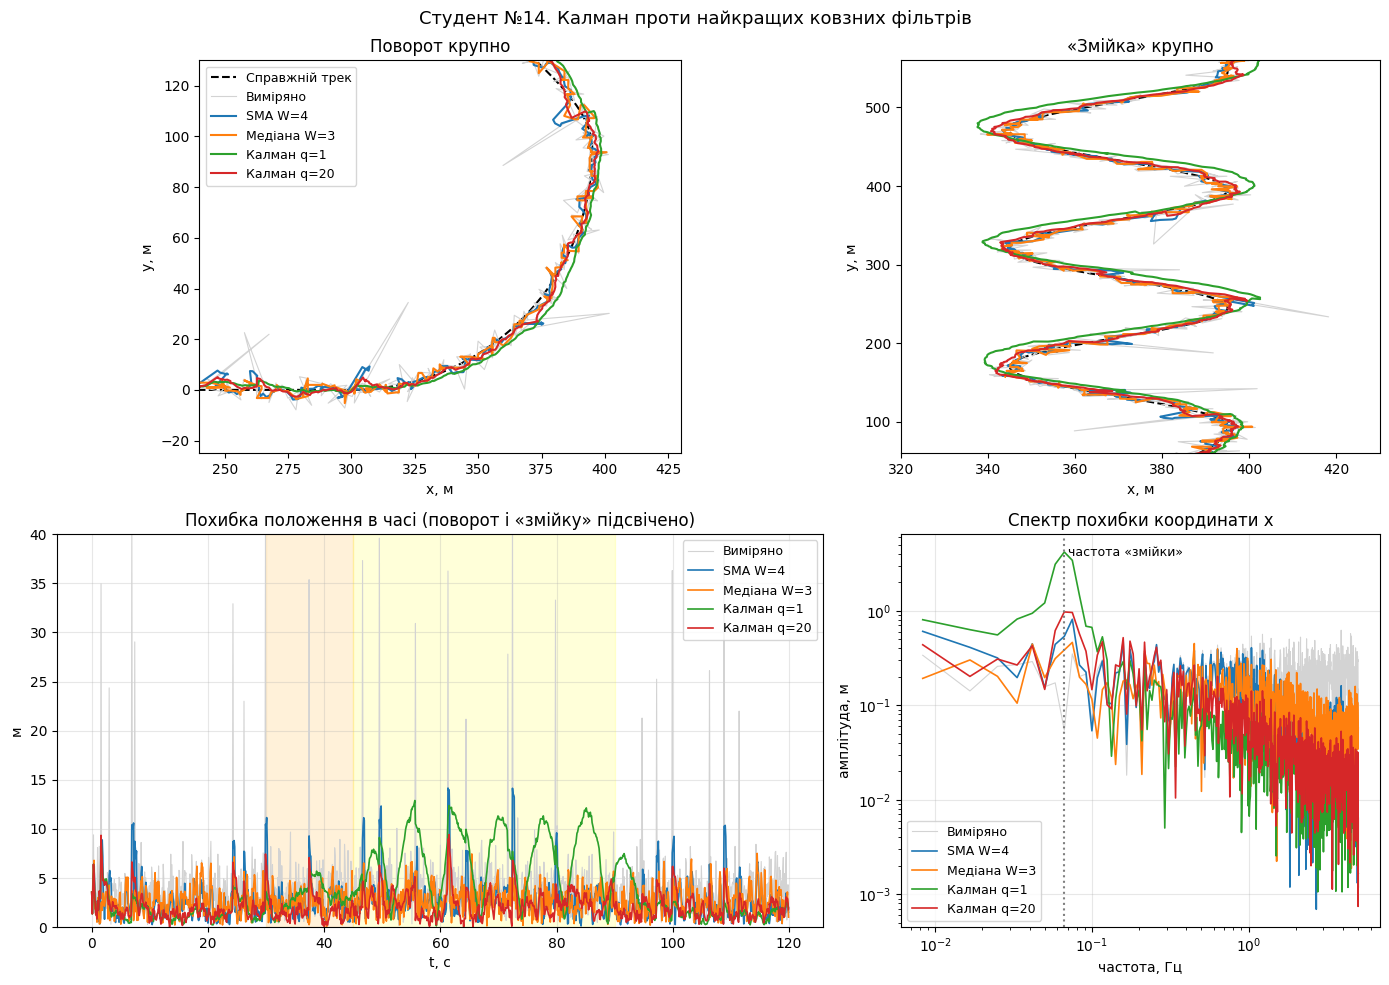

     SMA W=4: середня похибка на прямій (10–28 с) 2.36 м
  Калман q=1: середня похибка на прямій (10–28 с) 1.44 м
 Калман q=20: середня похибка на прямій (10–28 с) 1.64 м


In [10]:
compare({
    'SMA W=4': apply(lambda: SMA(4)),
    'Медіана W=3': apply(lambda: Median(3)),
    'Калман q=1': apply_kalman(1),
    'Калман q=20': apply_kalman(20)
}, 'Калман проти найкращих ковзних фільтрів')

straight = (T >= 10) & (T < 28)

for name, (xs, ys) in {
    'SMA W=4': apply(lambda: SMA(4)),
    'Калман q=1': apply_kalman(1),
    'Калман q=20': apply_kalman(20)
}.items():
    err = np.hypot(
        xs - X_TRUE,
        ys - Y_TRUE
    )[straight].mean()

    print(
        f'{name:>12}: середня похибка '
        f'на прямій (10–28 с) {err:.2f} м'
    )


In [11]:
filters = {
    'SMA W=4': apply(lambda: SMA(4)),
    'Медіана W=3': apply(lambda: Median(3)),
    'Калман q=1': apply_kalman(1),
    'Калман q=20': apply_kalman(20)
}

for name, (xs, ys) in filters.items():
    print(f'{name}: RMSE {rmse(xs, ys, skip=5):.2f} м')

SMA W=4: RMSE 3.43 м
Медіана W=3: RMSE 3.06 м
Калман q=1: RMSE 5.16 м
Калман q=20: RMSE 2.42 м


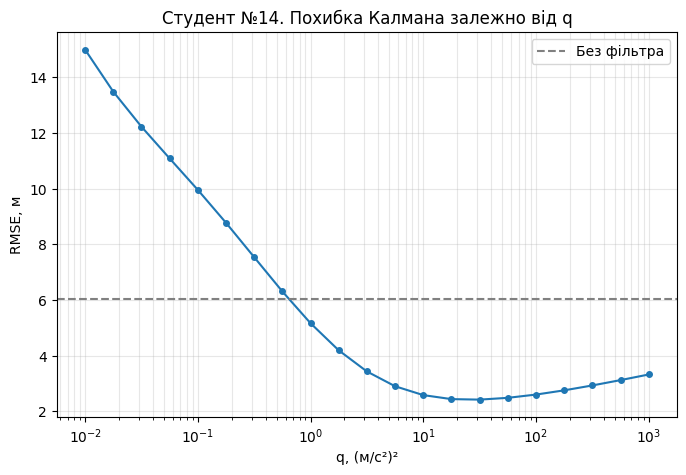

Найкраще q ≈ 31.6, RMSE 2.42 м


In [12]:
qs = np.logspace(-2, 3, 21)
errors = [rmse(*apply_kalman(q), skip=5) for q in qs]

plt.figure(figsize=(8, 5))
plt.semilogx(qs, errors, marker='o', ms=4)

plt.axhline(
    rmse(X_MEAS, Y_MEAS, skip=5),
    color='gray',
    ls='--',
    label='Без фільтра'
)

plt.xlabel('q, (м/с²)²')
plt.ylabel('RMSE, м')
plt.grid(alpha=0.3, which='both')
plt.legend()
plt.title(
    f'Студент №{STUDENT_NUMBER}. '
    'Похибка Калмана залежно від q'
)

plt.show()

print(
    f'Найкраще q ≈ {qs[int(np.argmin(errors))]:.3g}, '
    f'RMSE {min(errors):.2f} м'
)

                  Виміряно: RMSE   6.02 м
              Калман q=0.1: RMSE   9.96 м
             Калман q=1000: RMSE   3.32 м


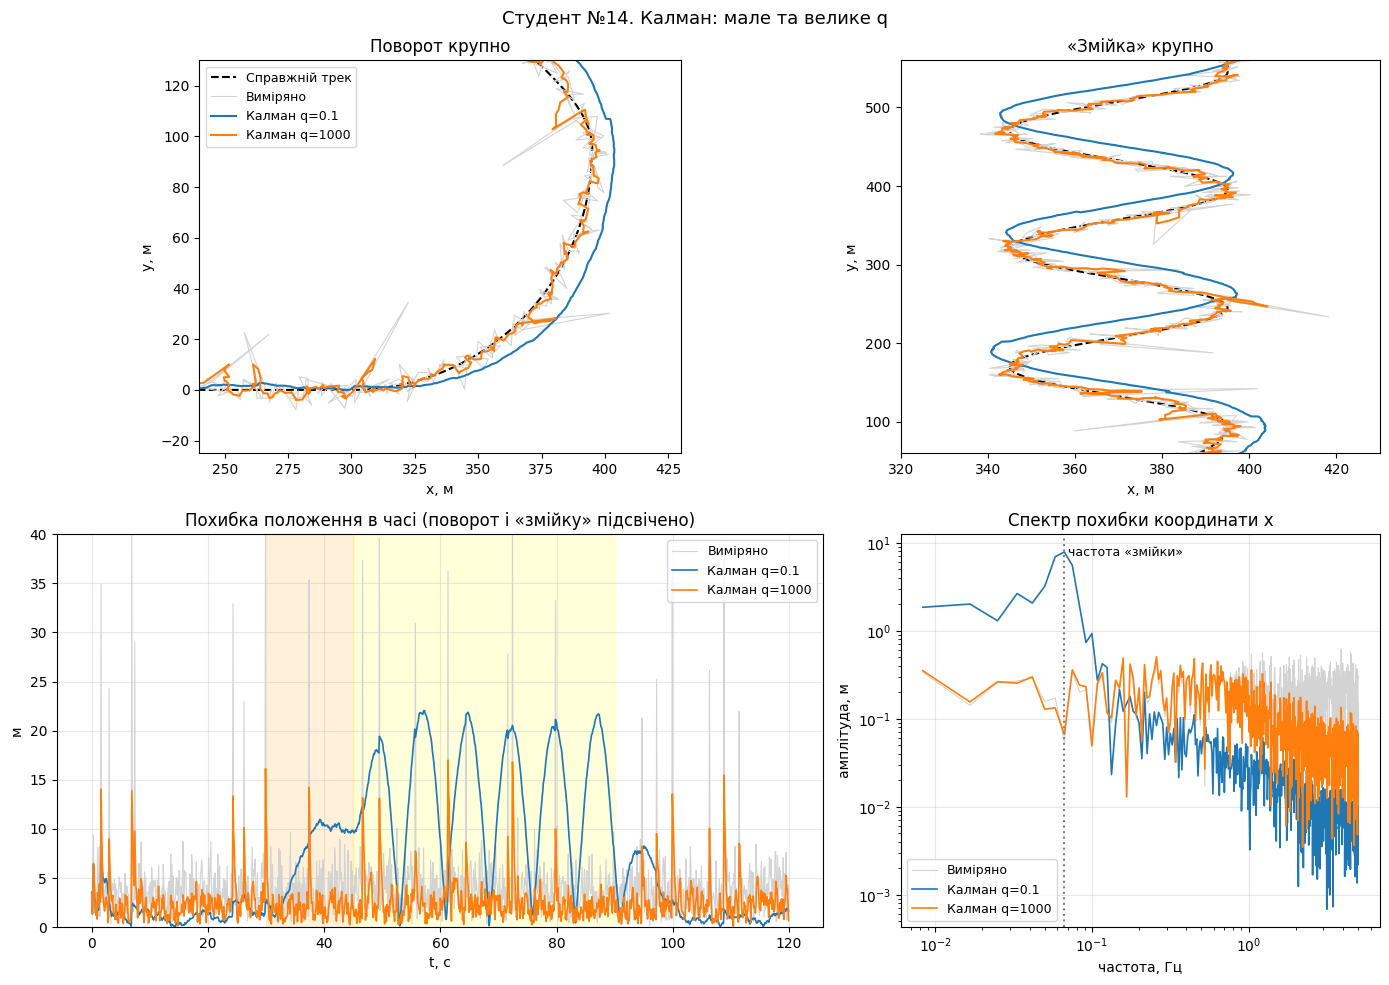

In [13]:
compare({
    'Калман q=0.1': apply_kalman(0.1),
    'Калман q=1000': apply_kalman(1000)
}, 'Калман: мале та велике q')

                  Виміряно: RMSE   6.02 м
               Калман q=20: RMSE   2.42 м
      Калман q=20 + gating: RMSE   2.07 м
     Калман q=0.5 + gating: RMSE   6.60 м


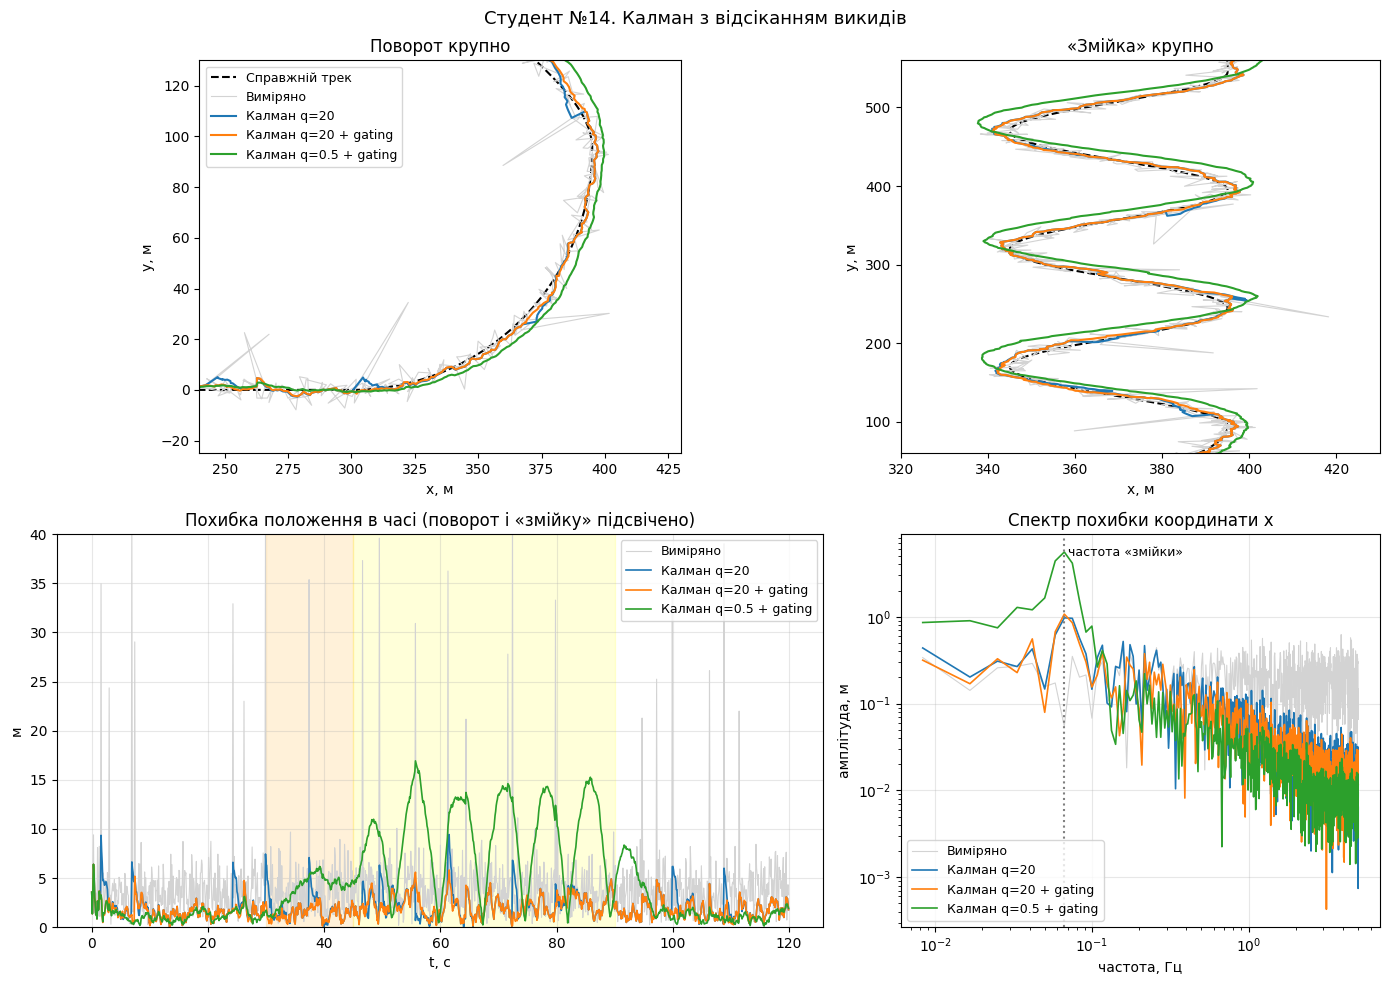

In [14]:
compare({
    'Калман q=20': apply_kalman(20),
    'Калман q=20 + gating': apply_kalman(20, gate=9.21),
    'Калман q=0.5 + gating': apply_kalman(0.5, gate=9.21)
}, 'Калман з відсіканням викидів')

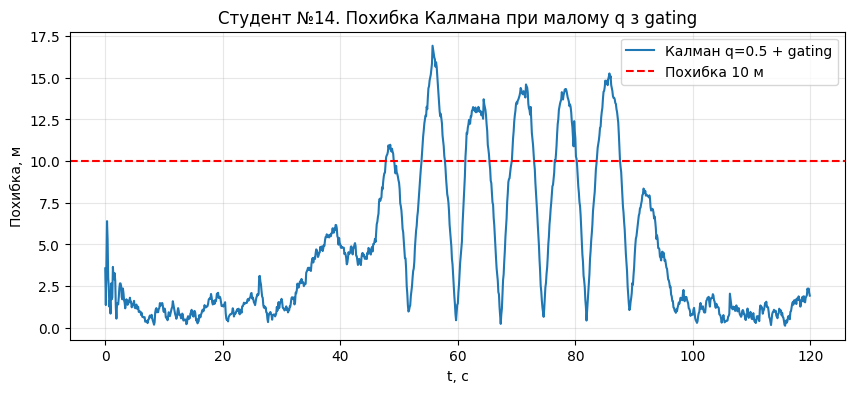

Перше перевищення 10 м: 47.8 с
Максимальна похибка: 16.92 м


In [15]:
xs, ys = apply_kalman(0.5, gate=9.21)

err = np.hypot(xs - X_TRUE, ys - Y_TRUE)

plt.figure(figsize=(10, 4))
plt.plot(T, err, label='Калман q=0.5 + gating')
plt.axhline(10, color='red', ls='--', label='Похибка 10 м')
plt.xlabel('t, с')
plt.ylabel('Похибка, м')
plt.grid(alpha=0.3)
plt.legend()
plt.title(
    f'Студент №{STUDENT_NUMBER}. '
    'Похибка Калмана при малому q з gating'
)
plt.show()

indices = np.flatnonzero(err > 10)

if len(indices):
    print(
        f'Перше перевищення 10 м: '
        f'{T[indices[0]]:.1f} с'
    )

print(f'Максимальна похибка: {err.max():.2f} м')

## Експерименти
Додавайте нижче по одній комірці на кожен пункт методички.